# 06.4 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/06-unsupervised/04-hierarchical/solutions.ipynb)

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

In [2]:
names = list("ABCDE")
points = np.array([[1, 1], [2, 1], [5, 4], [6, 5], [6, 8]], dtype=float)   # (orders, items per order)

## Exercise 1

1. A–B = 1.00 is smallest. **{A, B} at 1.00.**
2. C–D = 1.41. **{C, D} at 1.41.**
3. Complete-linkage distances (farthest pair):
   - {A, B}–{C, D}: max(5.00, 6.40, 4.24, 5.66) = 6.40
   - {A, B}–E: max(8.60, 8.06) = 8.60
   - {C, D}–E: max(4.12, 3.00) = **4.12**

   **{C, D, E} at 4.12.**
4. {A, B}–{C, D, E}: the farthest pair is A–E = **8.60**.

In [3]:
from scipy.cluster.hierarchy import linkage, fcluster
pd.DataFrame(linkage(points, method="complete"), columns=["group 1", "group 2", "height", "size"]).round(2)

,group 1,group 2,height,size
0,0.0,1.0,1.00,2.0
1,2.0,3.0,1.41,2.0
2,4.0,6.0,4.12,3.0
3,5.0,7.0,8.60,5.0


## Exercise 2

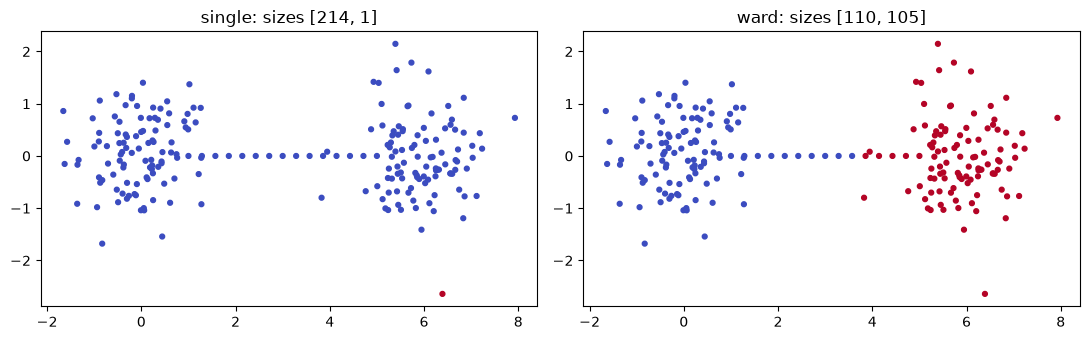

In [4]:
from sklearn.cluster import AgglomerativeClustering

rng = np.random.default_rng(0)
blob1 = rng.normal([0, 0], 0.7, size=(100, 2))
blob2 = rng.normal([6, 0], 0.7, size=(100, 2))
bridge = np.column_stack([np.linspace(1, 5, 15), np.zeros(15)])
pts = np.vstack([blob1, blob2, bridge])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, method in zip(axes, ["single", "ward"]):
    lab = AgglomerativeClustering(n_clusters=2, linkage=method).fit_predict(pts)
    ax.scatter(pts[:, 0], pts[:, 1], c=lab, cmap="coolwarm", s=12)
    ax.set_title(f"{method}: sizes {sorted(np.bincount(lab).tolist(), reverse=True)}")
plt.tight_layout(); plt.show()

**Ward** cuts the bridge in the middle and returns the two blobs (each with half the bridge). **Single** linkage follows the chain of bridge points: because every bridge point is close to its neighbour, the whole thing is one connected group, and the "second cluster" is whichever stray point is farthest from everything. This is the **chaining** problem.

## Exercise 3

In [5]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

snapshot = sales["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)    # 2011-12-10
rfm = sales.groupby("Customer ID").agg(
    recency=("InvoiceDate", lambda d: (snapshot - d.max()).days),
    frequency=("Invoice", "nunique"),
    monetary=("Revenue", "sum"))
print(f"{len(sales):,} rows, {len(rfm):,} customers, snapshot {snapshot.date()}")

392,693 rows, 4,338 customers, snapshot 2011-12-10


In [6]:
from sklearn.preprocessing import StandardScaler

sample = rfm.sample(300, random_state=42)
Xs = StandardScaler().fit_transform(np.log1p(sample))
print("sample:", Xs.shape)

sample: (300, 3)


In [7]:
from sklearn.cluster import KMeans
Z = linkage(Xs, method="ward")
ward4, ward5 = fcluster(Z, 4, "maxclust"), fcluster(Z, 5, "maxclust")
print("Ward: 5-cluster groups (rows) inside 4-cluster groups (columns)")
print(pd.crosstab(ward5, ward4))

km4 = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(Xs)
km5 = KMeans(n_clusters=5, n_init=10, random_state=42).fit_predict(Xs)
print("\nK-Means: k=5 groups (rows) vs k=4 groups (columns)")
print(pd.crosstab(km5, km4))

Ward: 5-cluster groups (rows) inside 4-cluster groups (columns)
col_0    1   2   3   4
row_0                 
1       49   0   0   0
2      109   0   0   0
3        0  12   0   0
4        0   0  63   0
5        0   0   0  67

K-Means: k=5 groups (rows) vs k=4 groups (columns)
col_0   0   1   2   3
row_0                
0       0   4  67   0
1       1   0   0  78
2      54   0   2   0
3       0  13   0   0
4       6   0  33  42


**Ward nests perfectly**: every row of its crosstab has exactly one non-zero cell. Going from 4 to 5 clusters splits one group in two and leaves the rest untouched, because both come from cutting the same tree.

**K-Means does not**: some $k = 5$ groups take customers from two different $k = 4$ groups. Re-running K-Means with a new $k$ redraws all the borders. If marketing needs groups and sub-groups that stay consistent, hierarchical clustering gives you that for free.